[Python, Visually](https://johnfisher-ai.github.io/Python-Visual-Guides/) &nbsp;&rsaquo;&nbsp; [GeoPandas, Deep Dive](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)

# Making Maps


## What you will be able to do

A map is a set of choices about layers, colors and projection, and each one changes what a reader
sees. Draw GeoDataFrames with `plot`, color the districts by a column, and choose the coordinate
system the map is drawn in.

## The idea

### The problem

The forecast office has a table of its eight districts with the number of stations in each and the
number per 10,000 km². The Mid district has 11.2 stations per 10,000 km² and the West district 8.0,
and the table says so precisely, but it cannot show that the thin districts of the north have about
as many stations for their size as the wide ones of the south, or that Svalbard has no stations at
all. Those are questions about where, and a map answers them.

A map is built from decisions about which shapes go underneath and which on top, which column sets
the colors and how its values are grouped into a few colors a reader can tell apart, and which
coordinate system flattens the curved Earth onto the page. Each decision changes what the reader sees,
and a wrong one gives a map that looks finished and misleads.

### A formal definition

> **`plot`** draws the geometries of a GeoDataFrame or GeoSeries on a Matplotlib axes, one shape per
> row, with the axes measured in the units of the data's CRS. Given a `column`, it colors each shape
> by that column's value, as a category with `categorical=True` or on a continuous color scale. Given
> a `scheme`, it first sorts the values into `k` classes with the mapclassify library, which makes a
> **choropleth**, a map whose areas are shaded by class.

### Why it works that way

The axes take the numbers in the geometries as they are. A layer in degrees and a layer in meters
drawn on the same axes land in different places, since 10 degrees and 10 meters are both just 10 to
Matplotlib, so every layer of one map is converted to one CRS first. Layers are drawn in the order
they are plotted, and each new one covers the ones before it.

In latitude and longitude GeoPandas stretches the axes so that a degree of longitude is drawn
narrower than a degree of latitude, as it is on the ground near the map's middle. A projected CRS in
meters needs no stretching, and UTM zone 33N draws Norway with little distortion. Web Mercator, the
CRS of most web maps, enlarges areas more the farther north they are.

A color scale with hundreds of shades is hard to read against a legend, so a choropleth groups the
values into a few classes. Equal intervals split the range of values into equal steps.
Quantiles put as near the same number of shapes in each class as the values allow. The same data can look even under one grouping
and uneven under the other, so the choice of grouping is part of what the map says.

### Where this shows up

Every report on places has maps in it. The **Why GeoPandas** notebook drew a first one, the
**Dissolve and Explode** notebook mapped regions, and the **A Station Atlas** notebook ends with a map.

### What this notebook covers

- one layer in latitude and longitude, and the same layer in UTM zone 33N
- several layers on one axes, in order
- colors from a category, from a number and from classes
- what Web Mercator does to Svalbard
- saving a map to a file, and interactive maps
- three mistakes when drawing maps

### A first look

Before any of the detail, here is the whole idea in a few lines. There is nothing to run yet: read it,
and read the output underneath it. Everything from Setup onward is where you start running things.

```python
import mapclassify

densities = [0.0, 8.0, 8.0, 8.7, 8.9, 9.0, 9.9, 11.2]
classes = mapclassify.Quantiles(densities, k=3)
print(classes.bins.round(2))
print(classes.yb)
```

```
[ 8.23  8.97 11.2 ]
[0 0 0 1 1 2 2 2]
```

The eight values are the districts' stations per 10,000 km². Quantiles with three classes gives the
upper edge of each class, 8.23, 8.97 and 11.2, and `yb` gives each value's class, three or two to a
class. A choropleth colors each district by that class.

## Setup

Two libraries for the tables, GeoPandas and Shapely for the geometry, mapclassify for the classes,
and Matplotlib for the maps.

- `Path` finds the guide's copy of the country outlines, and names the file one map is saved to
- `numpy` and `pandas` build the made-up register of stations
- `geopandas` draws every layer, and the cell prints its version
- `shapely` is the geometry library under GeoPandas, used here to build the districts
- `mapclassify` sorts values into classes, and the cell prints its version
- `matplotlib.pyplot` makes the figures and axes the layers are drawn on

`countries` holds the outlines of Denmark, Finland, Norway, Russia and Sweden. Made with Natural Earth.
The outlines come from Natural Earth's 1:50m map of the world's countries, which is in the public
domain.

`stations` is the register of 300 weather stations, and `named` is the five named stations, both in
latitude and longitude. `districts` is the eight forecast districts in UTM zone 33N. The stations and
the districts are made up. The stations are drawn at random over mainland Norway from a fixed seed, and
the districts are drawn around eight chosen centers and cut to Norway's outline.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import mapclassify
import matplotlib.pyplot as plt

COUNTRIES_URL = ("https://raw.githubusercontent.com/johnfisher-ai/Python-Visual-Guides/main/data/nordic-countries.geojson")
local_copy = Path("../../data/nordic-countries.geojson")
countries = gpd.read_file(local_copy if local_copy.exists() else COUNTRIES_URL)


weather_stations = pd.DataFrame({
    "name": ["Bergen", "Oslo", "Svalbard", "Tromso", "Kirkenes"],
    "latitude": [60.39, 59.91, 78.22, 69.65, 69.73],
    "longitude": [5.32, 10.75, 15.65, 18.96, 30.05],
})


def mainland_norway():
    """Norway's outline south of 74 degrees north, without Svalbard, in UTM zone 33N."""
    parts = countries[countries["ADMIN"] == "Norway"].to_crs(25833).explode()
    return parts[parts.geometry.bounds["maxy"] < 8_200_000].union_all()


def station_network(n=300, seed=2026):
    """A made-up register of weather stations on mainland Norway, one row each."""
    rng = np.random.default_rng(seed)
    land = mainland_norway()
    x_min, y_min, x_max, y_max = land.bounds
    east, north = [], []
    while len(east) < n:
        x, y = rng.uniform(x_min, x_max), rng.uniform(y_min, y_max)
        if land.contains(shapely.Point(x, y)):
            east.append(x)
            north.append(y)
    lonlat = gpd.GeoSeries(gpd.points_from_xy(east, north), crs=25833).to_crs(4326)
    return pd.DataFrame({
        "station": [f"NS{i:03d}" for i in range(1, n + 1)],
        "latitude": lonlat.y.round(4).to_numpy(), "longitude": lonlat.x.round(4).to_numpy(),
        "elevation_m": np.clip(rng.gamma(1.6, 220, n), 2, 1900).round(0).astype(int),
        "owner": rng.choice(["met", "road", "airport", "private"], n, p=[0.4, 0.3, 0.1, 0.2]),
        "installed": rng.integers(1950, 2025, n),
    })


DISTRICT_CENTERS = {"South": (8.0, 58.6), "East": (10.8, 60.5), "West": (6.0, 60.8), "Mid": (11.0, 63.6),
                    "North": (14.5, 67.0), "Far North": (19.0, 69.4), "Northeast": (25.5, 70.0),
                    "Svalbard": (16.0, 78.5)}


def forecast_districts():
    """Eight made-up forecast districts that cover Norway, in UTM zone 33N."""
    norway = countries[countries["ADMIN"] == "Norway"].to_crs(25833).geometry.iloc[0]
    centers = gpd.GeoSeries(gpd.points_from_xy(*zip(*DISTRICT_CENTERS.values())), crs=4326).to_crs(25833)
    cells = shapely.voronoi_polygons(shapely.MultiPoint(list(centers)),
                                     extend_to=shapely.box(*norway.buffer(200_000).bounds)).geoms
    names = [next(name for name, center in zip(DISTRICT_CENTERS, centers) if cell.contains(center))
             for cell in cells]
    districts = gpd.GeoDataFrame({"district": names}, geometry=[cell.intersection(norway) for cell in cells],
                                 crs=25833)
    return districts.set_index("district").loc[list(DISTRICT_CENTERS)].reset_index()


network = station_network()
stations = gpd.GeoDataFrame(
    network, geometry=gpd.points_from_xy(network["longitude"], network["latitude"]), crs=4326
)


named = gpd.GeoDataFrame(
    weather_stations,
    geometry=gpd.points_from_xy(weather_stations["longitude"], weather_stations["latitude"]),
    crs=4326,
)

districts = forecast_districts()
print("geopandas", gpd.__version__, "| mapclassify", mapclassify.__version__, "|", len(countries), "countries,",
      len(stations), "made-up stations,", len(districts), "made-up districts")

geopandas 1.2.0 | mapclassify 2.10.0 | 5 countries, 300 made-up stations, 8 made-up districts


## Worked examples

### A single layer in latitude and longitude

axes stretched by: 2.53


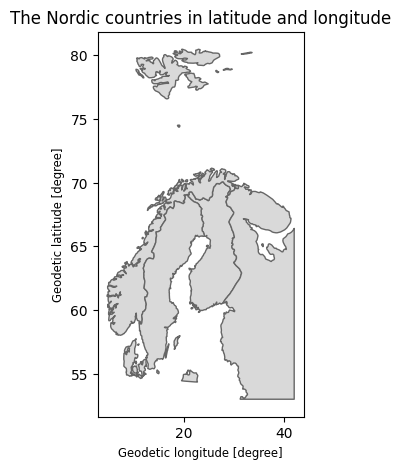

In [2]:
fig, ax = plt.subplots(figsize=(6, 5))
countries.plot(ax=ax, color="0.85", edgecolor="0.4")
ax.set_title("The Nordic countries in latitude and longitude")
print("axes stretched by:", round(ax.get_aspect(), 2))
plt.show()

The axes read in degrees. GeoPandas stretched them so that one degree up is drawn 2.53 times as long as
one degree across, the ratio of a degree of latitude to a degree of longitude near 67 degrees north,
the middle of the map. The stretch is right only there, so Svalbard is drawn too wide and Denmark too
narrow.

### The same layer in UTM zone 33N

axes stretched by: 1.0


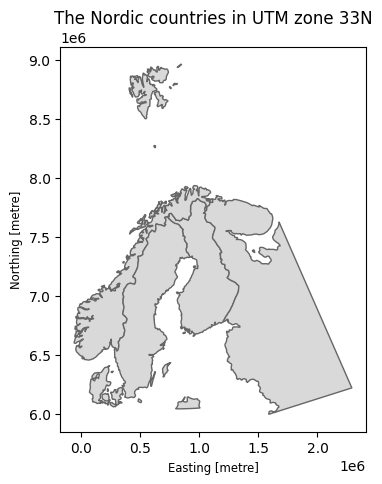

In [3]:
fig, ax = plt.subplots(figsize=(6, 5))
countries.to_crs(25833).plot(ax=ax, color="0.85", edgecolor="0.4")
ax.set_title("The Nordic countries in UTM zone 33N")
print("axes stretched by:", ax.get_aspect())
plt.show()

In meters the axes need no stretch, and a kilometer is the same length in both directions. UTM zone
33N is centered on 15 degrees east, and lines of equal longitude lean more the farther they are from
it. Russia's outline was cut at 42 degrees east, and that straight edge, upright on the first map, now
runs from upper left to lower right, its top tilted back toward 15 degrees east.

### Several layers on one axes

Each call to `plot` with `ax=ax` adds a layer on top of the ones before it. Every layer is in UTM zone
33N, so they line up.

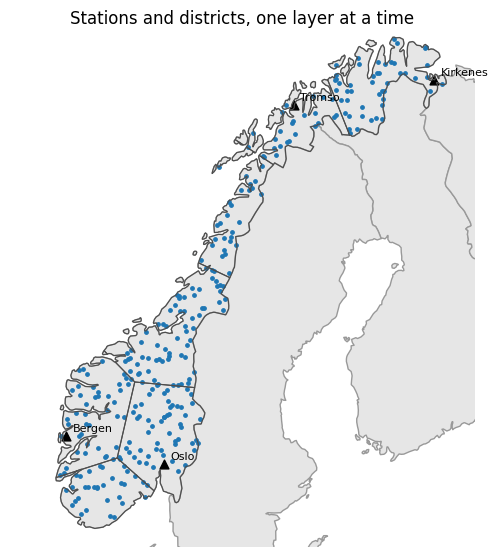

In [4]:
countries_m = countries.to_crs(25833)
stations_m = stations.to_crs(25833)
named_m = named.to_crs(25833)

fig, ax = plt.subplots(figsize=(6, 7))
countries_m.plot(ax=ax, color="0.9", edgecolor="0.6")
districts.boundary.plot(ax=ax, color="0.3", linewidth=0.8)
stations_m.plot(ax=ax, color="tab:blue", markersize=6)
named_m.plot(ax=ax, color="black", marker="^", markersize=40)
for name, point in zip(named_m["name"], named_m.geometry):
    ax.annotate(name, (point.x, point.y), xytext=(5, 3), textcoords="offset points", fontsize=8)
ax.set_xlim(-200_000, 1_200_000)
ax.set_ylim(6_400_000, 7_950_000)
ax.set_axis_off()
ax.set_title("Stations and districts, one layer at a time")
plt.show()

The countries are drawn first, so everything else sits on top of them. `boundary` turns the districts
into their outlines, which leaves the land showing through. `set_xlim` and `set_ylim` are in meters,
like the data, and `set_axis_off` hides the axes, whose numbers a reader of a map rarely needs.

### Colors from a category

`column` names the column that sets each shape's color, and `categorical=True` gives every value a
color of its own.

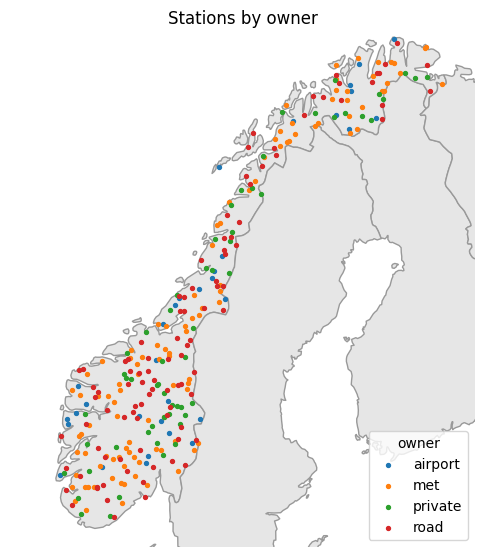

In [5]:
fig, ax = plt.subplots(figsize=(6, 7))
countries_m.plot(ax=ax, color="0.9", edgecolor="0.6")
stations_m.plot(ax=ax, column="owner", categorical=True, markersize=8, legend=True,
                legend_kwds={"loc": "lower right", "title": "owner"})
ax.set_xlim(-200_000, 1_200_000)
ax.set_ylim(6_400_000, 7_950_000)
ax.set_axis_off()
ax.set_title("Stations by owner")
plt.show()

The legend lists the four owners in alphabetical order. The colors come from Matplotlib's default set
for categories, one per value.

### Colors from a number

Without `categorical`, a column of numbers is drawn on a continuous scale, and `legend=True` adds a
color bar.

elevation from 2 to 1561 meters
stations below 500 meters: 229 of 300


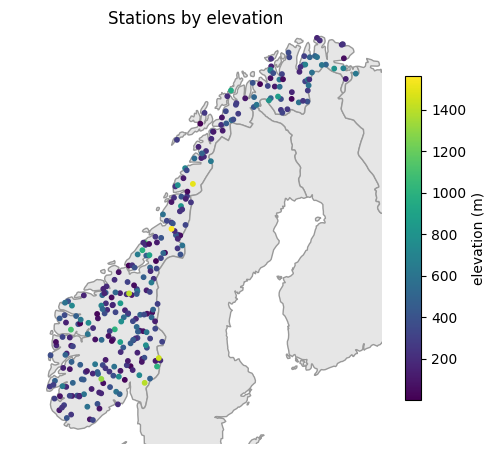

In [6]:
fig, ax = plt.subplots(figsize=(6, 7))
countries_m.plot(ax=ax, color="0.9", edgecolor="0.6")
stations_m.plot(ax=ax, column="elevation_m", cmap="viridis", markersize=10, legend=True,
                legend_kwds={"label": "elevation (m)", "shrink": 0.6})
print("elevation from", stations_m["elevation_m"].min(), "to", stations_m["elevation_m"].max(), "meters")
print("stations below 500 meters:", (stations_m["elevation_m"] < 500).sum(), "of", len(stations_m))
ax.set_xlim(-200_000, 1_200_000)
ax.set_ylim(6_400_000, 7_950_000)
ax.set_axis_off()
ax.set_title("Stations by elevation")
plt.show()

The color bar runs from the lowest elevation to the highest, 2 to 1,561 meters. 229 of the 300
stations are below 500 meters, so most points take the darker colors at the bottom of the scale. The elevations are
made up and drawn without regard to the land, so the map shows no mountain ranges.

### A choropleth of station density

Each district's stations per 10,000 km² come from a spatial join and the district's area.

In [7]:
placed = gpd.sjoin(stations_m, districts, how="left")
counts = placed.groupby("district").size().reindex(districts["district"], fill_value=0)
density = districts.assign(stations=counts.to_numpy())
density["per_10k_km2"] = (density["stations"] / (density.area / 1e6) * 10_000).round(1)
density.drop(columns="geometry")

,district,stations,per_10k_km2
0,South,32,8.9
1,East,56,9.0
2,West,43,8.0
3,Mid,69,11.2
4,North,27,8.7
5,Far North,25,8.0
6,Northeast,48,9.9
7,Svalbard,0,0.0


`scheme` sorts the values into classes before they are colored. The two schemes below divide the
same eight densities into three classes.

In [8]:
for scheme in ["Quantiles", "EqualInterval"]:
    classes = mapclassify.classify(density["per_10k_km2"], scheme, k=3)
    print(f"{scheme:14} upper edges {classes.bins.round(2).tolist()}  districts per class {classes.counts.tolist()}")

Quantiles      upper edges [8.23, 8.97, 11.2]  districts per class [3, 2, 3]
EqualInterval  upper edges [3.73, 7.47, 11.2]  districts per class [1, 0, 7]


Quantiles puts three, two and three districts in its classes. Equal intervals split the range from 0
to 11.2 into three equal steps, and Svalbard's 0 is alone in the lowest, the middle class is empty,
and the seven mainland districts share the top one.

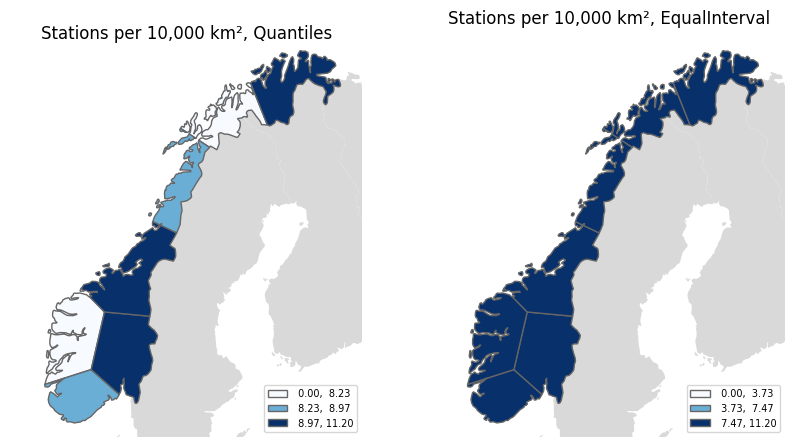

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 6))
for ax, scheme in zip(axes, ["Quantiles", "EqualInterval"]):
    countries_m.plot(ax=ax, color="0.85")
    density.plot(ax=ax, column="per_10k_km2", scheme=scheme, k=3, cmap="Blues", edgecolor="0.4",
                 legend=True, legend_kwds={"loc": "lower right", "fontsize": 7})
    ax.set_xlim(-200_000, 1_200_000)
    ax.set_ylim(6_400_000, 7_950_000)
    ax.set_axis_off()
    ax.set_title(f"Stations per 10,000 km², {scheme}")
plt.show()

With quantiles the mainland shows all three shades. West and Far North, at 8.0, are lightest, with
Svalbard off the map, and East, Mid and Northeast are darkest. East's 9.0 and South's 8.9 differ by a
tenth and fall in different classes. With equal intervals the whole mainland is one shade, since every
mainland district falls in the top class. Both maps state their edges in the legend, and each one
shows only the differences its classes separate.

### What Web Mercator does to Svalbard

EPSG:3857, Web Mercator, keeps shapes right in a small area and makes areas grow toward the poles.

In [10]:
areas = pd.DataFrame({
    "district": districts["district"],
    "UTM km²": districts.area / 1e6,
    "equal-area km²": districts.to_crs(3035).area / 1e6,
    "Web Mercator km²": districts.to_crs(3857).area / 1e6,
})
areas["times"] = areas["Web Mercator km²"] / areas["equal-area km²"]
mainland = areas.iloc[:7]
print("mainland, equal-area:", round(mainland["equal-area km²"].sum()), "km² | Web Mercator:",
      round(mainland["Web Mercator km²"].sum()), "km²")
print("UTM against equal-area, largest difference:",
      round(((areas["UTM km²"] / areas["equal-area km²"] - 1).abs() * 100).max(), 2), "%")
areas.iloc[[0, 3, 6, 7]].round({"UTM km²": 0, "equal-area km²": 0, "Web Mercator km²": 0, "times": 1})

mainland, equal-area: 324256 km² | Web Mercator: 1784528 km²
UTM against equal-area, largest difference: 0.42 %


,district,UTM km²,equal-area km²,Web Mercator km²,times
0,South,36056.0,35919.0,134624.0,3.7
3,Mid,61575.0,61559.0,308121.0,5.0
6,Northeast,48523.0,48360.0,410279.0,8.5
7,Svalbard,62068.0,62099.0,1664057.0,26.8


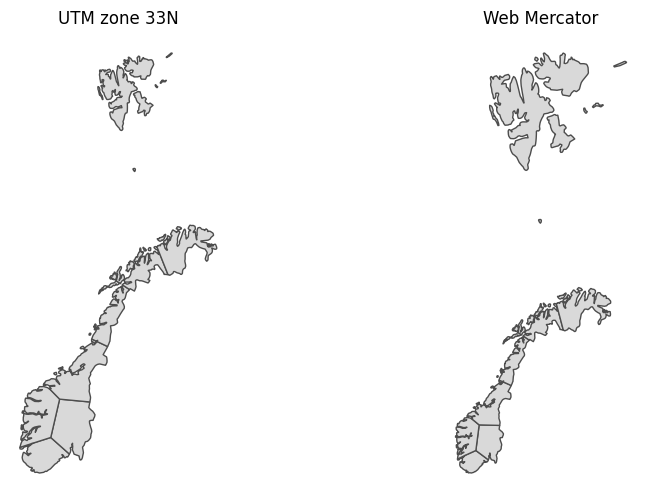

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 6))
districts.plot(ax=axes[0], color="0.85", edgecolor="0.3")
axes[0].set_title("UTM zone 33N")
districts.to_crs(3857).plot(ax=axes[1], color="0.85", edgecolor="0.3")
axes[1].set_title("Web Mercator")
for ax in axes:
    ax.set_axis_off()
plt.show()

The equal-area column is measured in EPSG:3035, the equal-area projection for Europe, which keeps
areas everywhere on the continent. Svalbard's district measures 62,099 km² there and is drawn as
1,664,057 km² in Web Mercator, 26.8 times its size, while the South district is drawn 3.7 times its
size. The seven mainland districts together measure 324,256 km² and are drawn as 1,784,528 km², so on
the right Svalbard looks almost as large as the whole mainland, which is more than five times its
size. Web Mercator suits a map that is zoomed into a small place, and a map that compares areas across
many latitudes belongs in an equal-area CRS, such as EPSG:3035. For Norway alone, UTM zone 33N gives
areas within half a percent, 0.42% at most for these districts.

### Saving a map to a file, and interactive maps with explore

`savefig` writes the figure to a file, here a PNG at 150 dots per inch, which the cell then removes.

In [12]:
fig, ax = plt.subplots(figsize=(6, 7))
density.plot(ax=ax, column="per_10k_km2", scheme="Quantiles", k=3, cmap="Blues", edgecolor="0.4")
ax.set_axis_off()
path = Path("station-density.png")
fig.savefig(path, dpi=150, bbox_inches="tight")
plt.close(fig)
print(path.name, "written:", path.exists())
path.unlink()

station-density.png written: True


`plt.close` stops the figure from also being shown in the notebook. GeoPandas also has `explore()`,
which draws a GeoDataFrame as an interactive web map with the folium library, on top of map tiles that
the browser downloads, and that you can zoom and pan in Colab. It writes a new random identifier into
the page every time it runs, so this guide describes it and does not run it.

## Your turn

Five tasks. Write your answer in the cell under each task and run it.

Try a task before you look at its answer. Reading a solution teaches you much less than
getting there yourself, even slowly.

When you are ready: [**open the solutions notebook**](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/12-making-maps-solutions.ipynb).

**1.** Draw the countries in UTM zone 33N colored by `POP_EST`, with `scheme="Quantiles"`, `k=3` and a legend.

In [13]:
# your code here

**2.** Draw the network stations colored by the year they were installed, in four equal-interval classes, over the countries in gray.

In [14]:
# your code here

**3.** Draw a map of the Northeast district with its stations colored by owner, and Kirkenes as a black triangle.

In [15]:
# your code here

**4.** Print the class that `mapclassify.Quantiles` with `k=4` gives each district's density, beside the district's name.

In [16]:
# your code here

**5.** Draw the districts in latitude and longitude, EPSG:4326, beside the same districts in UTM zone 33N, and print how much GeoPandas stretched the axes of the first.

In [17]:
# your code here

## Common errors

### `ValueError: Invalid scheme: 'quantile'`

`plot` creates a figure and its axes before it checks the scheme, so a cell that raised here would show
the traceback with an empty frame under it. This cell catches the error, prints its message as the
traceback's last line would, and closes the empty figure with `plt.close("all")`. When you make this
mistake in a cell of your own, you will see both.

In [18]:
try:
    density.plot(column="per_10k_km2", scheme="quantile", k=3)
except ValueError as error:
    print(f"ValueError: {error}")
plt.close("all")

ValueError: Invalid scheme: 'quantile'
Scheme must be in the set: dict_keys(['boxplot', 'equalinterval', 'fisherjenks', 'fisherjenkssampled', 'headtailbreaks', 'jenkscaspall', 'jenkscaspallforced', 'jenkscaspallsampled', 'maxp', 'maximumbreaks', 'naturalbreaks', 'quantiles', 'percentiles', 'prettybreaks', 'stdmean', 'userdefined'])


The message's second line lists every scheme by its lowercase name, and the one wanted is `quantiles`,
plural. GeoPandas matches the name without regard to case, so `"Quantiles"`, the class name in
mapclassify, works as well.

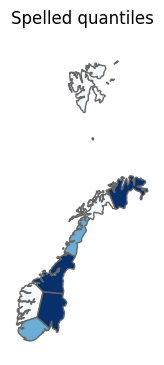

In [19]:
fig, ax = plt.subplots(figsize=(4, 4))
density.plot(ax=ax, column="per_10k_km2", scheme="quantiles", k=3, cmap="Blues", edgecolor="0.4")
ax.set_axis_off()
ax.set_title("Spelled quantiles")
plt.show()

### `KeyError: 'population'`

`plot` opens its figure before it looks the column up, so this cell also catches the error, prints the
message and closes the empty figure.

In [20]:
try:
    countries.plot(column="population")
except KeyError as error:
    print(f"KeyError: {error}")
plt.close("all")

KeyError: 'population'


`column` must be the name of a column in the table, and Natural Earth calls the population `POP_EST`.
pandas looked the name up and did not find it, and the error names only the missing key. Print
`countries.columns` when unsure of a name.

In [21]:
print(list(countries.columns))

['ADMIN', 'ADM0_A3', 'ISO_A3', 'POP_EST', 'POP_YEAR', 'CONTINENT', 'geometry']


### No error, and two layers far apart

x from -120668 to 1172265
y from -448106 to 9411395
aspect: 2.53


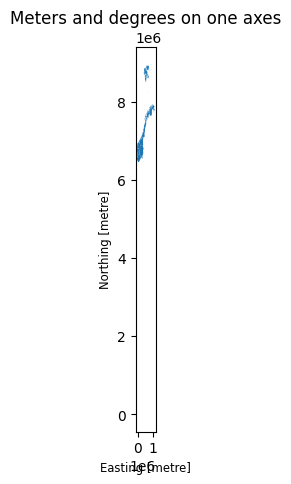

In [22]:
fig, ax = plt.subplots(figsize=(5, 5))
districts.plot(ax=ax, color="tab:blue")
countries.plot(ax=ax, color="tab:red")
print("x from", round(ax.get_xlim()[0]), "to", round(ax.get_xlim()[1]))
print("y from", round(ax.get_ylim()[0]), "to", round(ax.get_ylim()[1]))
print("aspect:", round(ax.get_aspect(), 2))
ax.set_title("Meters and degrees on one axes")
plt.show()

The districts are in meters and the countries in degrees. The countries' numbers, under 82 in either
direction, shrink to a speck at the origin, too small to see, while the axes stretch to millions to
hold the districts. The countries were drawn last, so GeoPandas set the axes' stretch for degrees,
2.53, which squeezes the districts into a thin strip. Nothing warns, because GeoPandas does not
compare a new layer's CRS with the layers already on the axes, and Matplotlib receives only numbers.
Convert every layer to one CRS before drawing, as the worked examples do with `to_crs(25833)`.

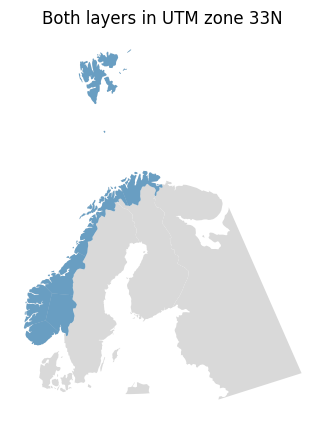

In [23]:
fig, ax = plt.subplots(figsize=(5, 5))
countries.to_crs(districts.crs).plot(ax=ax, color="0.85")
districts.plot(ax=ax, color="tab:blue", alpha=0.6)
ax.set_axis_off()
ax.set_title("Both layers in UTM zone 33N")
plt.show()

## Recap

- You can draw a GeoDataFrame with `plot`, in latitude and longitude or in a projected CRS.
- You can stack several layers on one axes, all in the same CRS, in the order they should cover each
  other.
- You can color shapes by a category, by a number with a color bar, or by classes from a mapclassify
  scheme.
- You can see why Web Mercator misleads about areas far north, and save a map to a file.

## What is next

The **A Station Atlas** notebook puts the guide together, from a register of coordinates to a finished
map and a GeoPackage.

---

&#8592; **Previous:** [Dissolve and Explode](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/11-dissolve-and-explode.ipynb)  &nbsp;·&nbsp;  [GeoPandas, Deep Dive Notebooks](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)  &nbsp;·&nbsp;  **Next:** [A Station Atlas](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/13-a-station-atlas.ipynb) &#8594;
